# Demo giữa kỳ — Phân cụm 63 tỉnh Việt Nam với STING trên dữ liệu PAPI

**Đồ án môn Học máy** · Topic 6: *Grid-based (clustering)* · Domain: Sociology / History · Nhóm 2 người.

**Thời lượng:** 15 phút trình bày + 5 phút Q&A.

**Dữ liệu:** PAPI 2011–2024 (63 tỉnh × 14 năm; panel `882×41` đã kiểm chứng). STING **tự viết từ đầu** (`src/sting.py`), scikit-learn chỉ dùng cho baselines/metrics.

## Bố cục buổi trình bày

| Phần | Nội dung | Phút |
|---|---|---|
| 1 | Vấn đề & ý tưởng grid-based; STING là gì | 3' |
| 2 | Demo thuật toán trên dữ liệu giả lập (thấy rõ cơ chế lưới) | 3' |
| 3 | Dữ liệu thật PAPI + audit thang đo | 2' |
| 4 | Kết quả phân cụm + **pipeline dự đoán** | 5' |
| 5 | Hạn chế trung thực & kế hoạch cuối kỳ | 2' |

> Mọi số liệu trong notebook được tính lại từ dữ liệu khi chạy lại — không hardcode.

In [1]:
import sys
from pathlib import Path

for cand in (Path.cwd(), Path.cwd().parent):
    if (cand / "src" / "sting.py").exists():
        sys.path.insert(0, str(cand / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score

from sting import STING

plt.rcParams["figure.dpi"] = 110
print("import OK")

import OK


## 1. Vì sao grid-based? STING là gì?

- Phân cụm truyền thống (k-means, DBSCAN) không giả định gì về **hình dạng cụm** khi dùng lưới:
  mỗi ô lưới lưu **thống kê cục bộ**, không cần gán cụm toàn cục trước.
- **STING** (Wang, Yang & Muntz — VLDB 1997): chia không gian thành lưới **phân cấp** theo factor;
  mỗi ô lưu `count/mean/std/min/max` theo từng chiều; gom các ô "dày" (count ≥ `min_count`)
  liền kề thành cụm; điểm thuộc ô không dày = **nhiễu (-1)**.
- Chi phí xây lưới: **O(n)** theo số điểm (mỗi mức quét 1 lượt); truy vấn vùng chữ nhật dùng thống kê ô.

## 2. Demo nhanh trên dữ liệu giả lập

Hai blob 2D tách biệt — trường hợp "dễ" để kiểm chứng thuật toán chạy **đúng** trước khi dùng dữ liệu thật.

ARI = 0.950 | nhiễu = 2.5% | cụm = 2


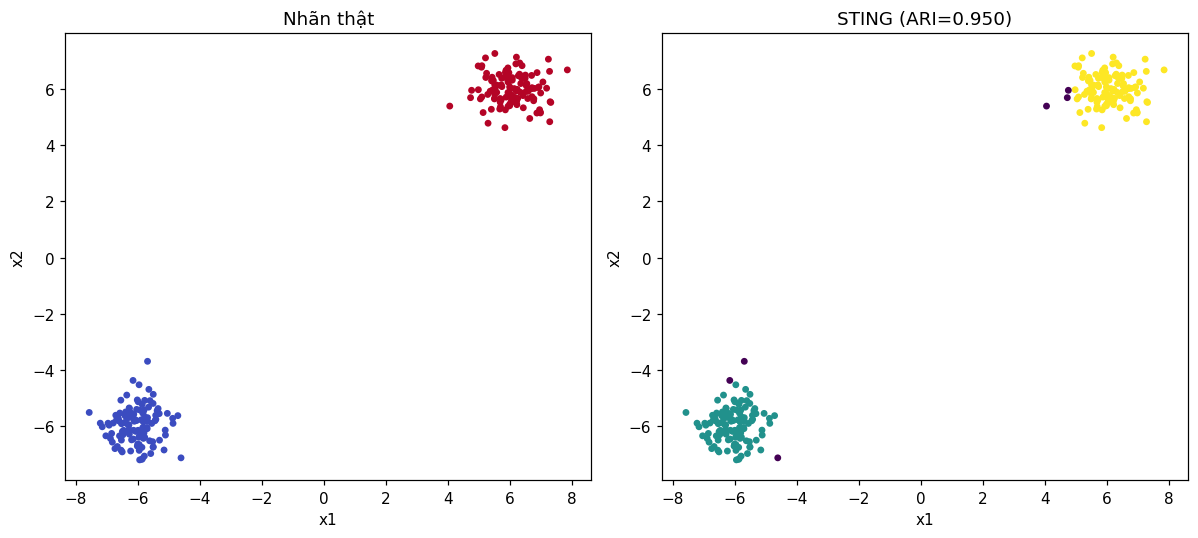

In [2]:
X, y_true = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                       cluster_std=0.6, random_state=42)

model = STING(n_levels=3, factor=4, min_count=3).fit(X)
labels = model.cluster(level=2, connectivity=1)
print(f"ARI = {adjusted_rand_score(y_true, labels):.3f} | nhiễu = {(labels == -1).mean():.1%} | cụm = {model.n_clusters_}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, s=12, cmap="coolwarm")
axes[0].set_title("Nhãn thật")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[1].scatter(X[:, 0], X[:, 1], c=labels, s=12, cmap="viridis")
axes[1].set_title(f"STING (ARI={adjusted_rand_score(y_true, labels):.3f})")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
plt.tight_layout()
plt.show()

In [3]:
level = 2
print("Thống kê ô ở mức", level)
cells = model.cells_[level]
rows = sorted(cells.items(), key=lambda kv: -kv[1].count)[:5]
for (idx, cell) in rows:
    print(f"  ô {idx}: count={cell.count}, mean=({cell.mean[0]:+.2f}, {cell.mean[1]:+.2f})")
print(f"Tổng: {len(cells)} ô có dữ liệu; STING quét mỗi mức 1 lượt => O(n)")

Thống kê ô ở mức 2
  ô (1, 1): count=45, mean=(-6.14, -5.84)
  ô (14, 14): count=36, mean=(+6.29, +5.85)
  ô (13, 14): count=23, mean=(+5.48, +5.91)
  ô (1, 0): count=22, mean=(-6.09, -6.68)
  ô (14, 15): count=17, mean=(+6.32, +6.58)
Tổng: 21 ô có dữ liệu; STING quét mỗi mức 1 lượt => O(n)


## 3. Dữ liệu thật: PAPI 2011–2024

- 14 workbook gốc (papi.org.vn) → panel sạch `province × year × d1..d8 + 30 sub-dim`.
- **Cảnh báo quan trọng phát hiện khi làm sạch:** 23/37 cột chỉ tiêu có **gãy thang đo**
  giữa các năm (vd `sd_5_4` đổi 0.25–2.5 → 0.33–3.33 tại 2021) — `check_data.py` tự audit;
  phân tích xuyên năm chỉ dùng chỉ tiêu qua audit (hoặc ghi rõ cách xử lý).
- 0.0 = "tỉnh không có đủ dữ liệu" → quy về NaN (khớp quy ước gói replication Mendeley).

In [4]:
panel = pd.read_csv("../data/processed/papi_panel_63_2011_2024.csv")
print("Panel:", panel.shape)
print("Tỉnh:", panel.province_code.nunique(), "| Năm:", panel.year.min(), "→", panel.year.max())
print()
missing = panel.isna().mean().sort_values(ascending=False)
print("Thiếu nhiều nhất:")
print((missing * 100).head(3).round(1).to_string())
print()
num_cols = panel.select_dtypes("number").shape[1]
print(f"Cột số: {num_cols} (yêu cầu ≥ 10) — đáp ứng")

Panel: (882, 41)
Tỉnh: 63 | Năm: 2011 → 2024

Thiếu nhiều nhất:
sd_8_3    58.0
sd_2_4    51.2
sd_8_1    50.9

Cột số: 39 (yêu cầu ≥ 10) — đáp ứng


In [5]:
# Audit thang đo (xem scripts/check_data.py để biết quy tắc đầy đủ)
means = panel.groupby("year").mean(numeric_only=True)
flags = []
for c in [c for c in panel.columns if c.startswith(("d", "sd_"))]:
    m = means[c].dropna()
    if len(m) >= 5:
        j = m.diff().abs().max()
        if j > 0.25:
            flags.append((c, round(j, 2)))
print("Cột bị đánh dấu gãy thang đo:", len(flags))
print("Ví dụ:", flags[:8])
print()
print("Chỉ tiêu được dùng trong pipeline dự đoán (qua audit): sd_4_2, sd_6_1, sd_1_3, sd_1_4, sd_4_1, sd_4_3, sd_4_4, sd_6_3")

Cột bị đánh dấu gãy thang đo: 23
Ví dụ: [('d1', np.float64(0.55)), ('d2', np.float64(0.43)), ('d3', np.float64(0.68)), ('d4', np.float64(0.33)), ('d5', np.float64(0.29)), ('d6', np.float64(0.71)), ('d7', np.float64(0.99)), ('d8', np.float64(0.64))]

Chỉ tiêu được dùng trong pipeline dự đoán (qua audit): sd_4_2, sd_6_1, sd_1_3, sd_1_4, sd_4_1, sd_4_3, sd_4_4, sd_6_3


## 4. Kết quả phân cụm thật

Cặp chỉ tiêu chốt (qua quy trình train-only — chọn trên ≤2020, kiểm trên 2021–2022, **không nhìn 2024**):

`4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công × 6.1 Y tế công lập`

In [6]:
import json
cfg = json.load(open("../models/predict_config.json", encoding="utf-8"))
print("Config đã đóng băng (predict_sweep.py):")
print("  features:", cfg["features"])
print("  STING:", cfg["sting"])
print("  chọn trên:", cfg["selection_protocol"])

Config đã đóng băng (predict_sweep.py):
  features: ['sd_4_2', 'sd_6_1']
  STING: {'n_levels': 3, 'factor': 4, 'min_count': 5, 'cluster_level': 2, 'connectivity': 1}
  chọn trên: Fit ≤2020; chấm trên tương lai giả 2021–2022; 2024 không tham gia chọn. Lọc: k 2–6, noise≤0.25, largest≤0.85, coverage≥0.75. Điểm = coverage - 0.5*noise - 0.15*largest - 0.02*|k-3| + 0.03*stable(mc±1).


In [7]:
summary = pd.read_csv("../results/predict_all_years.csv")
print(summary.groupby("split").size().to_dict())
for y in (2023, 2024):
    sub = summary[summary.year == y]
    print(y, "phân bố cụm:", dict(sorted(sub.pred_cluster.value_counts().items())))

{'test': 61, 'train': 808}
2023 phân bố cụm: {-1: 9, 2: 52}
2024 phân bố cụm: {-1: 13, 2: 48}


![Dự đoán cụm 2024](../results/figs/predict_2024.png)

**Đọc hình (trung thực):** dữ liệu PAPI khá đồng nhất — một vùng dày lớn + nhóm ngoại vi nhỏ;
năm 2024: 48/61 tỉnh có đủ chỉ tiêu vào cụm lớn, 13 tỉnh rơi vào ô thưa (nhiễu). Độ nhạy theo
`min_count` được ghi trong `results/predict_summary.md`.

In [8]:
figs = ["../results/figs/predict_2024.png", "../results/figs/sting_first_real.png",
        "../results/figs/supervised_regression.png"]
for f in figs:
    p = Path(f)
    print(("OK " if p.exists() else "THIẾU ") + f, f"({p.stat().st_size / 1024:.0f} KB)" if p.exists() else "")

OK ../results/figs/predict_2024.png (148 KB)
OK ../results/figs/sting_first_real.png (103 KB)
OK ../results/figs/supervised_regression.png (91 KB)


## 5. Pipeline dự đoán (2 mô hình local)

1. **STING.predict** (không giám sát): gán tỉnh vào ô lưới đã học; điểm ngoài vùng học → −1.
2. **Model giám sát Ridge/RF**: dự báo *6.1 Y tế công lập* năm sau từ 8 chỉ tiêu sạch năm nay
   — Ridge thắng baseline carry-forward ~10% MAE trên holdout 2023→2024 (xem `results/supervised_summary.md`).

Cả hai lưu **local** (`models/`), nạp lại để dự báo mà không cần huấn luyện lại.

In [9]:
sup = pd.read_csv("../results/supervised_metrics.csv")
print(sup.to_string(index=False))

          task                               model                      metric_cv  value_cv  holdout_mae  holdout_rmse  holdout_r2  holdout_acc  holdout_macro_f1
    regression carry-forward (giữ giá trị năm nay)       r2 (GroupKFold theo năm)       NaN       0.0683        0.0875       0.198          NaN               NaN
    regression                    trung bình train       r2 (GroupKFold theo năm)       NaN       0.0814        0.1027      -0.105          NaN               NaN
    regression                               ridge       r2 (GroupKFold theo năm)     0.451       0.0640        0.0768       0.382          NaN               NaN
    regression                       random forest       r2 (GroupKFold theo năm)     0.432       0.0616        0.0742       0.423          NaN               NaN
classification                majority (lớp đa số) f1_macro (GroupKFold theo năm)       NaN          NaN           NaN         NaN        0.814             0.449
classification              

## 6. Hạn chế trung thực & kế hoạch cuối kỳ

**Hạn chế:**
- Dữ liệu PAPI **khá đồng nhất** — cấu trúc cụm yếu ở cấp tỉnh/năm; số liệu được báo cáo kèm nhiễu.
- **Gãy thang đo** ở nhiều sub-dim (23/37 cột) — chỉ dùng chỉ tiêu qua audit; phân tích xuyên năm bị giới hạn.
- `d7/d8` chỉ có từ 2018 → robustness 8 chiều chỉ làm cho 2018–2024; giai đoạn 2011–2017 dùng d1–d6.
- Metric hình học (silhouette/DB/CH) **không bản địa** với lưới song song trục — chỉ so sánh thô, tách noise.
- Kết quả âm tính (phân loại ngoại vi không vượt baseline) được **giữ lại trung thực**.

**Cuối kỳ sẽ làm thêm:** so sánh STING vs k-means/DBSCAN (bảng metrics), robustness PCA, bản đồ 63 tỉnh,
tiến hóa cụm 2011–2024, báo cáo .docx + bảo vệ.

## 7. Câu hỏi phản biện trước (5 câu)

1. *Vì sao grid-based?* — Không giả định hình dạng cụm; O(n); phù hợp khi cụm kéo dài theo trục.
2. *STING khác DBSCAN/k-means thế nào?* — Lưới phân cấp + thống kê ô; DBSCAN theo mật độ kề điểm; k-means theo centroid.
3. *Chọn `min_count` sao?* — Sweep tham số; cấu hình chốt bằng quy trình train-only (không nhìn test).
4. *Noise −1 là gì?* — Điểm thuộc ô không dày — STING không ép mọi điểm vào cụm; ta tách noise khỏi metrics.
5. *Ý nghĩa cho chính sách?* — Nhóm ngoại vi nhỏ gợi ý "hai tốc độ" quản trị dịch vụ công giữa các tỉnh; cần thêm dữ liệu định tính để diễn giải.

Chi tiết ≥10 câu: `reports/qa_midterm.md`.